# Macroeconomic Regimes and Tactical Asset Allocation

**Research question:** does the macroeconomic regime (growth and inflation accelerating or decelerating) help explain, and exploit, the returns of different asset classes?

The notebook is organised in six steps:

1. **Data**: macro variables from FRED and ETF prices from Yahoo Finance
2. **Regimes**: classify every month into one of four macro regimes
3. **Analysis**: how each asset performs in each regime
4. **Strategy**: a portfolio that changes weights with the regime, compared with a 60/40
5. **Machine learning**: forecasting "stocks or bonds?" with a walk-forward test
6. **Conclusions and limitations**

**How to use it:** in Colab, *Runtime → Run all*. It takes about a minute. Charts are saved in the `figures/` folder (folder icon on the left).

> Research and educational project. Not investment advice.

In [1]:
!pip install -q yfinance

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figures", exist_ok=True)

# --- Project parameters -----------------------------------------------------
START = "2005-01-01"          # start of price download
TRANSACTION_COST = 0.0010     # 10 basis points per unit of turnover
MIN_TRAIN = 60                # minimum training months for machine learning

REGIME_COLORS = {
    "Goldilocks":  "#2e7d32",  # growth ↑ inflation ↓
    "Reflation":   "#f9a825",  # growth ↑ inflation ↑
    "Stagflation": "#c62828",  # growth ↓ inflation ↑
    "Deflation":   "#1565c0",  # growth ↓ inflation ↓
}
REGIME_ORDER = list(REGIME_COLORS)

## Step 1: Data

**Macro variables (FRED, the St. Louis Fed database):**

| Variable | What it measures |
|---|---|
| Industrial production (12-month change) | **Growth**. Used instead of GDP because it is monthly |
| CPI (12-month change) | **Inflation** |
| Unemployment rate | Labour-market cycle |
| Fed Funds rate | **Monetary policy** |
| 10-year minus 2-year spread | Slope of the yield curve. When negative, it has historically preceded recessions |
| BAA credit spread | Premium investors demand for corporate default risk |

**Publication lag.** January CPI is released in mid-February. If the model used it at the end of January, it would exploit information nobody had at the time (*look-ahead bias*). Monthly macro data are therefore shifted forward by one month. The spreads are daily market data, known at month end, so they are not shifted.

**Assets (ETFs):** US equities (SPY), 7-10 year Treasuries (IEF), gold (GLD), commodities (DBC), US dollar (UUP). The sample starts in 2007 because UUP exists from then.

In [3]:
# FRED code -> (name, publication lag in months)
FRED_SERIES = {
    "INDPRO":   ("industrial_production", 1),
    "CPIAUCSL": ("cpi", 1),
    "UNRATE":   ("unemployment", 1),
    "FEDFUNDS": ("fed_funds", 0),
    "T10Y2Y":   ("curve_10y_2y", 0),
    "BAA10Y":   ("credit_spread", 0),
}

ASSETS = {
    "SPY": "us_equities",
    "IEF": "treasuries_7_10y",
    "GLD": "gold",
    "DBC": "commodities",
    "UUP": "us_dollar",
}
ASSET_NAMES = list(ASSETS.values())


def load_fred(series_id):
    # Download a FRED series (CSV format, no API key needed) and convert it to month end
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    return df.iloc[:, 0].astype(float).resample("ME").last()


def build_macro():
    macro = pd.DataFrame({name: load_fred(code) for code, (name, _) in FRED_SERIES.items()})

    # Fill isolated missing months (e.g. October 2025 CPI, never published because of the
    # US government shutdown). One gap would otherwise break the 12-month calculations.
    macro = macro.interpolate(limit=2, limit_area="inside")

    # For growth and inflation what matters is the change, not the level
    macro["growth_yoy"] = macro["industrial_production"].pct_change(12, fill_method=None) * 100
    macro["inflation_yoy"] = macro["cpi"].pct_change(12, fill_method=None) * 100
    macro = macro.drop(columns=["industrial_production", "cpi"])

    # Publication lag
    lags = {name: lag for _, (name, lag) in FRED_SERIES.items()}
    lags["growth_yoy"] = lags["industrial_production"]
    lags["inflation_yoy"] = lags["cpi"]
    for col in macro.columns:
        macro[col] = macro[col].shift(lags[col])
    return macro


def build_returns():
    prices = yf.download(list(ASSETS), start=START, auto_adjust=True, progress=False)["Close"]
    monthly = prices.resample("ME").last()           # month-end price
    return monthly.pct_change(fill_method=None).rename(columns=ASSETS)[ASSET_NAMES]


macro = build_macro()   # long history (from the 1940s for some series): needed for moving averages
returns = build_returns()
data = macro.join(returns, how="inner").dropna()
data.index.name = "date"

print(f"Sample: {data.index[0]:%Y-%m} -> {data.index[-1]:%Y-%m} ({len(data)} months)")
data.tail()

Sample: 2007-04 -> 2026-10 (235 months)


,unemployment,fed_funds,curve_10y_2y,credit_spread,growth_yoy,inflation_yoy,us_equities,treasuries_7_10y,gold,commodities,us_dollar
date,,,,,,,,,,,
2026-06-30,4.30,3.63,0.30,1.53,1.74,4.17,-0.01,0.00,-0.12,-0.10,0.03
2026-07-31,4.20,3.63,0.47,1.63,1.46,3.46,0.00,-0.01,0.01,0.10,-0.01
2026-08-31,4.10,3.63,0.41,1.59,1.28,3.30,0.03,0.00,0.10,0.06,-0.00
2026-09-30,4.10,3.75,0.41,1.47,1.62,3.35,-0.00,-0.03,-0.07,0.03,0.02
2026-10-31,4.20,3.88,0.38,1.53,2.25,3.72,-0.01,0.03,-0.07,0.04,0.01


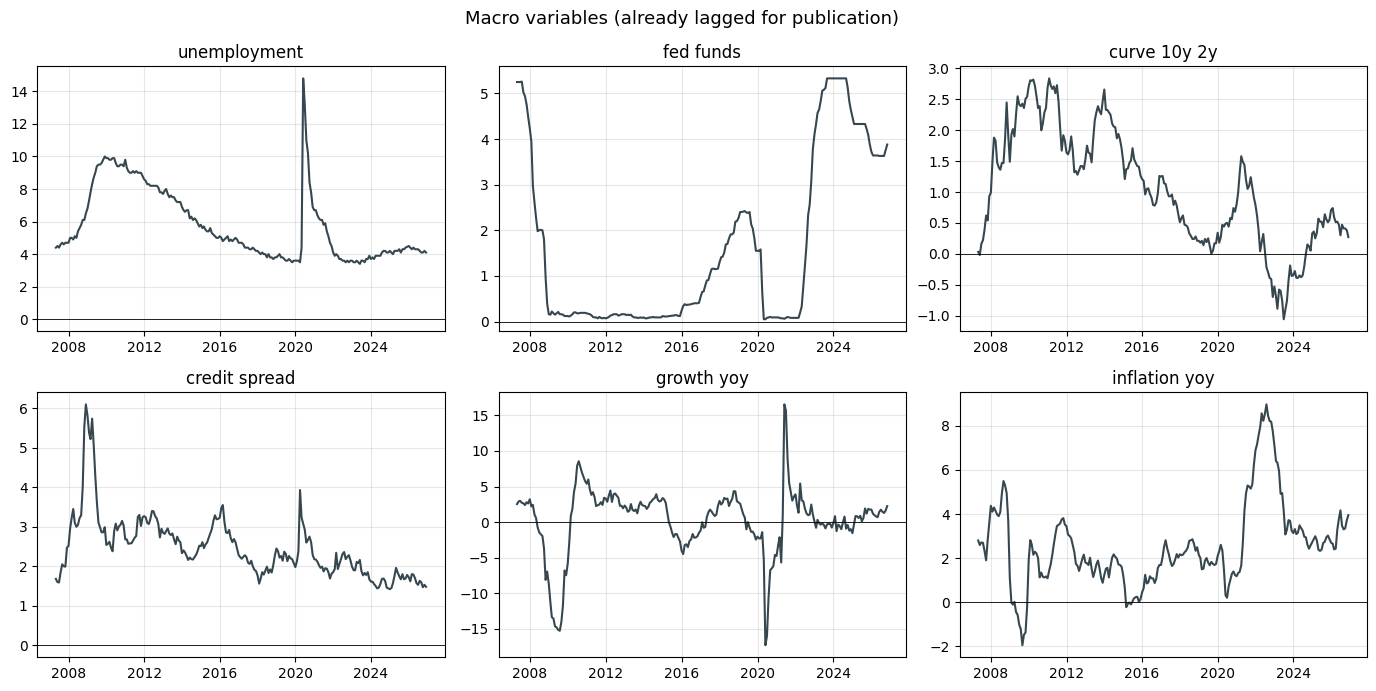

In [4]:
# Macro variables over the sample period
macro_plot = macro.loc[data.index[0]:]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, macro_plot.columns):
    ax.plot(macro_plot.index, macro_plot[col], color="#37474f")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(col.replace("_", " "))
fig.suptitle("Macro variables (already lagged for publication)", fontsize=13)
fig.tight_layout()
fig.savefig("figures/01_macro_variables.png", dpi=150)
plt.show()

## Step 2: Classifying the regimes

For each month we look at **direction**, not level:

- growth is **accelerating** if 12-month growth is above its average of the previous 12 months;
- inflation is **rising** if 12-month inflation is above its average of the previous 12 months.

The moving average only uses past data, so it introduces no look-ahead. Combining the two directions gives four regimes:

| | Inflation ↓ | Inflation ↑ |
|---|---|---|
| **Growth ↑** | Goldilocks | Reflation |
| **Growth ↓** | Deflation | Stagflation |

In [5]:
growth_up = macro["growth_yoy"] > macro["growth_yoy"].rolling(12).mean()
inflation_up = macro["inflation_yoy"] > macro["inflation_yoy"].rolling(12).mean()

regime = pd.Series(
    np.select(
        [growth_up & ~inflation_up, growth_up & inflation_up,
         ~growth_up & inflation_up, ~growth_up & ~inflation_up],
        ["Goldilocks", "Reflation", "Stagflation", "Deflation"],
        default="",
    ),
    index=macro.index,
)
# Where the moving average cannot be computed, the regime is undefined
undefined = macro["growth_yoy"].rolling(12).mean().isna() | macro["inflation_yoy"].rolling(12).mean().isna()
regime[undefined] = ""

data["regime"] = regime.reindex(data.index)
data = data[data["regime"] != ""]

print("Months per regime:")
print(data["regime"].value_counts().reindex(REGIME_ORDER))

Months per regime:
regime
Goldilocks     46
Reflation      67
Stagflation    49
Deflation      73
Name: count, dtype: int64


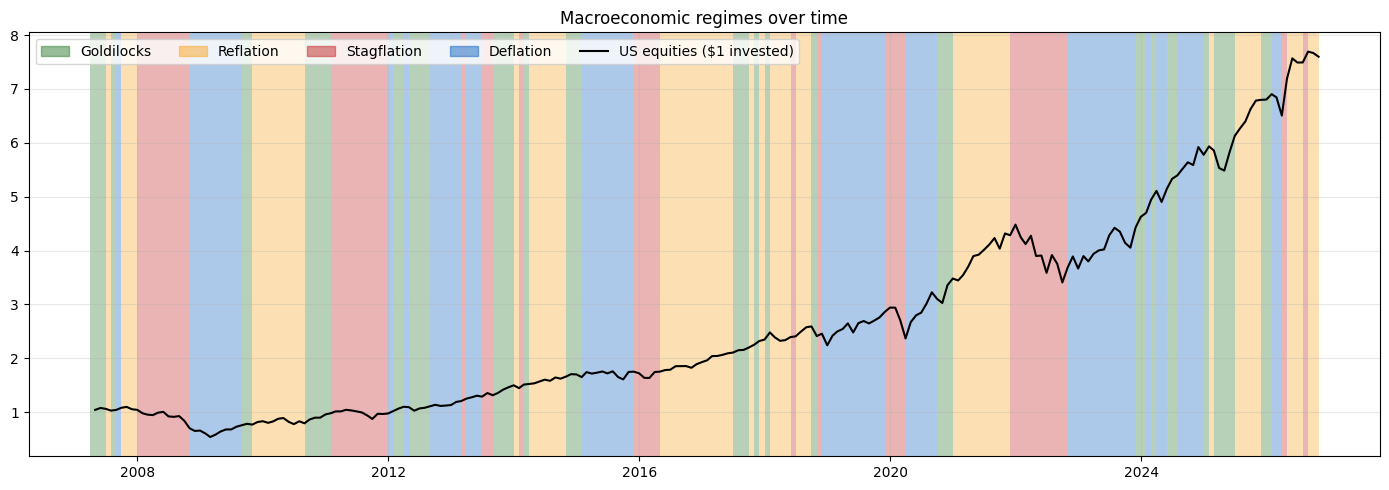

In [6]:
# Regime timeline, with the cumulative value of US equities on top
cum_equities = (1 + data["us_equities"]).cumprod()
fig, ax = plt.subplots(figsize=(14, 5))
for date, reg in data["regime"].items():
    ax.axvspan(date - pd.offsets.MonthEnd(1), date, color=REGIME_COLORS[reg], alpha=0.35, lw=0)
line, = ax.plot(cum_equities.index, cum_equities, color="black", lw=1.5)
patches = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in REGIME_COLORS.values()]
ax.legend(patches + [line], REGIME_ORDER + ["US equities ($1 invested)"], loc="upper left", ncol=5)
ax.set_title("Macroeconomic regimes over time")
fig.tight_layout()
fig.savefig("figures/02_regime_timeline.png", dpi=150)
plt.show()

## Step 3: How each asset performs in each regime

**Timing.** The regime known at the **end of month t** is compared with returns in **month t+1**. This measures a relationship an investor could actually have exploited, not just a contemporaneous correlation.

For each asset-regime pair we compute:
- **annualised mean return** (monthly mean × 12);
- **annualised volatility** (monthly standard deviation × √12);
- **t-statistic** of the mean: whether the average return is distinguishable from zero or could be noise. As a rule of thumb, |t| > 2 indicates a statistically significant result.

In [7]:
analysis = data[ASSET_NAMES].copy()
analysis["regime"] = data["regime"].shift(1)   # regime at end of t -> return in t+1
analysis = analysis.dropna()

groups = analysis.groupby("regime")[ASSET_NAMES]
ann_return = (groups.mean() * 12 * 100).reindex(REGIME_ORDER)
ann_vol = (groups.std() * np.sqrt(12) * 100).reindex(REGIME_ORDER)
t_stat = (groups.mean() / (groups.std() / np.sqrt(groups.count()))).reindex(REGIME_ORDER)

print("Annualised mean return (%) in the month after the regime signal")
display(ann_return)
print("\nAnnualised volatility (%)")
display(ann_vol)
print("\nt-statistic of the mean return")
display(t_stat)

Annualised mean return (%) in the month after the regime signal


,us_equities,treasuries_7_10y,gold,commodities,us_dollar
regime,,,,,
Goldilocks,21.39,1.88,20.60,17.22,-1.46
Reflation,12.49,4.62,10.42,8.73,3.11
Stagflation,-11.97,6.17,5.18,-12.45,5.96
Deflation,19.87,0.98,6.60,3.49,1.04



Annualised volatility (%)


,us_equities,treasuries_7_10y,gold,commodities,us_dollar
regime,,,,,
Goldilocks,10.74,5.81,15.68,15.84,6.89
Reflation,11.81,5.73,16.63,16.14,7.11
Stagflation,21.09,8.58,22.21,26.05,8.87
Deflation,15.31,6.76,16.34,17.55,7.91



t-statistic of the mean return


,us_equities,treasuries_7_10y,gold,commodities,us_dollar
regime,,,,,
Goldilocks,3.90,0.63,2.57,2.13,-0.42
Reflation,2.48,1.89,1.47,1.27,1.03
Stagflation,-1.15,1.45,0.47,-0.97,1.36
Deflation,3.20,0.36,1.00,0.49,0.32


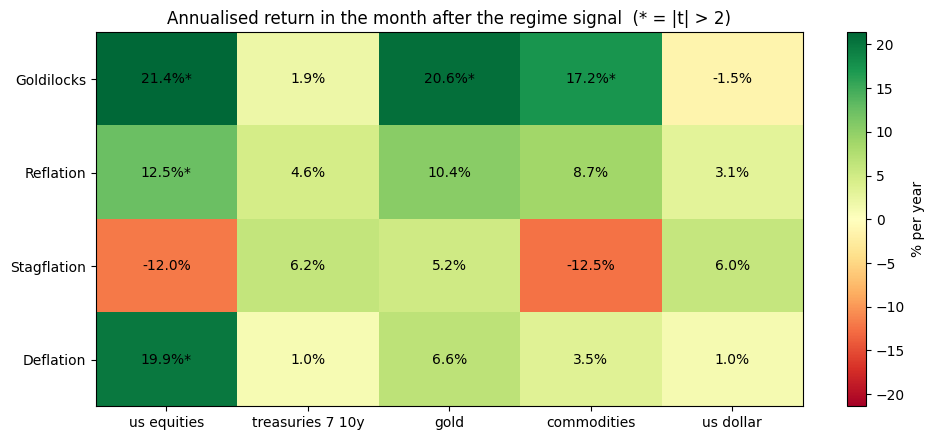

In [8]:
# Heatmap of returns by regime
fig, ax = plt.subplots(figsize=(10, 4.5))
lim = np.nanmax(np.abs(ann_return.values))
im = ax.imshow(ann_return.values, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(ASSET_NAMES)), [a.replace("_", " ") for a in ASSET_NAMES])
ax.set_yticks(range(len(REGIME_ORDER)), REGIME_ORDER)
for i in range(ann_return.shape[0]):
    for j in range(ann_return.shape[1]):
        value, t = ann_return.iloc[i, j], t_stat.iloc[i, j]
        star = "*" if abs(t) > 2 else ""
        ax.text(j, i, f"{value:.1f}%{star}", ha="center", va="center", fontsize=10)
ax.grid(False)
fig.colorbar(im, ax=ax, label="% per year")
ax.set_title("Annualised return in the month after the regime signal  (* = |t| > 2)")
fig.tight_layout()
fig.savefig("figures/03_regime_heatmap.png", dpi=150)
plt.show()

## Step 4: Tactical strategy based on regimes

**Rule:** at the end of each month I observe the regime and choose portfolio weights for the following month.

**Careful with the choice of weights.** They are not taken from the Step 3 heatmap. That would be cheating: we would use full-sample results to decide what to do at the start of the sample (*look-ahead bias* in strategy design). Instead, weights come **from economic theory**, fixed before looking at the data:

| Regime | Rationale | Weights |
|---|---|---|
| Goldilocks | Rising earnings, stable rates | 70% equities, 30% Treasuries |
| Reflation | Strong demand and rising prices | 40% equities, 40% commodities, 20% gold |
| Stagflation | Worst case for both stocks and bonds | 50% gold, 30% US dollar, 20% Treasuries |
| Deflation | Rate cuts, flight to safety | 70% Treasuries, 20% gold, 10% equities |

**Costs.** Every time weights change I pay 10 basis points on the value traded (*turnover*).

**Benchmarks:** 60/40 (60% equities, 40% Treasuries), equal weight across the five assets, equities only.

In [9]:
REGIME_WEIGHTS = {
    "Goldilocks":  {"us_equities": 0.70, "treasuries_7_10y": 0.30},
    "Reflation":   {"us_equities": 0.40, "commodities": 0.40, "gold": 0.20},
    "Stagflation": {"gold": 0.50, "us_dollar": 0.30, "treasuries_7_10y": 0.20},
    "Deflation":   {"treasuries_7_10y": 0.70, "gold": 0.20, "us_equities": 0.10},
}


def backtest(target_weights, asset_returns, cost=TRANSACTION_COST):
    # target_weights at row t = decision taken at end of month t -> applied to month t+1
    weights = target_weights.shift(1).dropna()
    r = asset_returns.loc[weights.index, weights.columns]
    gross = (weights * r).sum(axis=1)
    turnover = weights.diff().abs().sum(axis=1)
    turnover.iloc[0] = weights.iloc[0].abs().sum()       # initial purchase
    return gross - turnover * cost


def constant_weights(weights, index):
    return pd.DataFrame([weights] * len(index), index=index).reindex(columns=ASSET_NAMES).fillna(0.0)


def performance(r):
    value = (1 + r).cumprod()
    years = len(r) / 12
    vol = r.std() * np.sqrt(12)
    return pd.Series({
        "Annual return %": (value.iloc[-1] ** (1 / years) - 1) * 100,
        "Volatility %": vol * 100,
        "Sharpe (no rf)": r.mean() * 12 / vol,
        "Max drawdown %": (value / value.cummax() - 1).min() * 100,
    })


macro_weights = pd.DataFrame([REGIME_WEIGHTS[r] for r in data["regime"]], index=data.index)
macro_weights = macro_weights.reindex(columns=ASSET_NAMES).fillna(0.0)

R = data[ASSET_NAMES]
strategies = {
    "Macro regimes": backtest(macro_weights, R),
    "60/40": backtest(constant_weights({"us_equities": 0.6, "treasuries_7_10y": 0.4}, data.index), R),
    "Equal weight": backtest(constant_weights({a: 1 / len(ASSET_NAMES) for a in ASSET_NAMES}, data.index), R),
    "Equities only": backtest(constant_weights({"us_equities": 1.0}, data.index), R),
}
strategy_table = pd.DataFrame({k: performance(v) for k, v in strategies.items()}).T
strategy_table

,Annual return %,Volatility %,Sharpe (no rf),Max drawdown %
Macro regimes,7.93,8.94,0.90,-12.36
60/40,7.98,9.47,0.86,-29.46
Equal weight,6.20,6.71,0.93,-17.95
Equities only,10.71,15.44,0.74,-50.78


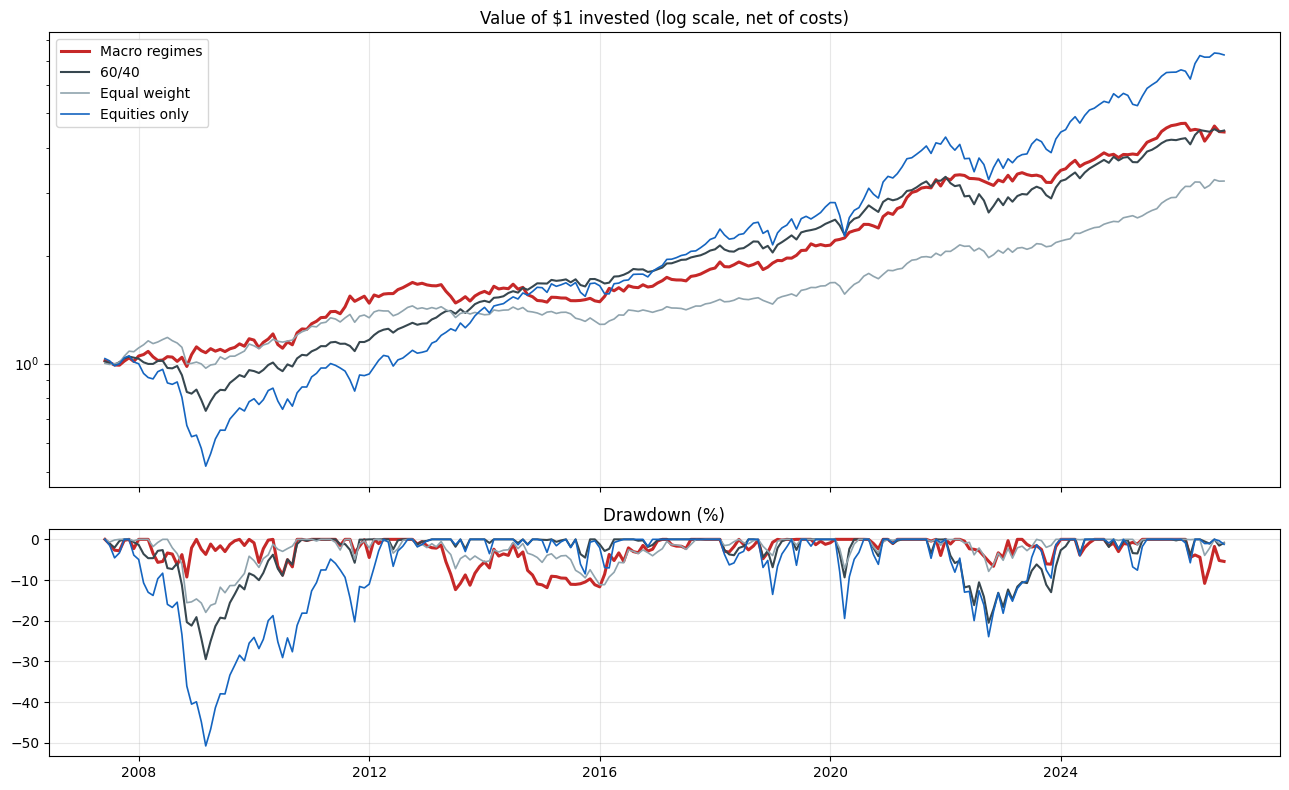

Macro strategy: sensitivity to transaction costs


,Annual return %,Sharpe (no rf)
0 bp,8.36,0.95
10 bp,7.93,0.90
30 bp,7.07,0.81
50 bp,6.21,0.72


Regime switches: 60 over 235 months


In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
styles = {"Macro regimes": ("#c62828", 2.2), "60/40": ("#37474f", 1.5),
          "Equal weight": ("#90a4ae", 1.2), "Equities only": ("#1565c0", 1.2)}
for name, r in strategies.items():
    color, lw = styles[name]
    value = (1 + r).cumprod()
    ax1.plot(value.index, value, label=name, color=color, lw=lw)
    ax2.plot(value.index, (value / value.cummax() - 1) * 100, color=color, lw=lw)
ax1.set_yscale("log")
ax1.set_title("Value of $1 invested (log scale, net of costs)")
ax1.legend()
ax2.set_title("Drawdown (%)")
fig.tight_layout()
fig.savefig("figures/04_strategy_backtest.png", dpi=150)
plt.show()

# Robustness: how much do transaction costs matter?
sensitivity = pd.DataFrame({
    f"{int(c * 1e4)} bp": performance(backtest(macro_weights, R, cost=c))[["Annual return %", "Sharpe (no rf)"]]
    for c in [0.0, 0.0010, 0.0030, 0.0050]
}).T
print("Macro strategy: sensitivity to transaction costs")
display(sensitivity)
switches = (data["regime"] != data["regime"].shift()).sum() - 1
print(f"Regime switches: {switches} over {len(data)} months")

## Step 5: Machine learning, stocks or bonds next month?

Instead of setting rules by hand, we let a model learn from the data. The question is simple and very "macro": **will equities beat Treasuries next month?** It is the classic *risk-on / risk-off* decision.

**Features, all known at the end of month t:** the macro variables, their 3-month changes, and the 12-month relative momentum of equities versus bonds.

**Walk-forward test.** This is the key point. Every month the model is re-trained **only on past data** and forecasts the following month, exactly as an analyst would have done in real time. Testing starts after 60 months of training.

**Two models:**
- **Logistic regression**: simple and interpretable; its coefficients show which variables matter;
- **Random forest**: captures non-linear relationships but is more prone to overfitting. Shallow trees limit this.

**The honest comparison.** Accuracy must be compared with a naive model that always predicts the outcome that was most frequent in the past. If equities beat bonds in 60% of months, 60% accuracy is worth nothing.

**Strategy:** if the model predicts equities, 80% equities and 20% Treasuries; otherwise 20% equities and 80% Treasuries.

In [11]:
# --- Features (known at end of month t) ----------------------------------------
features = macro.copy()
for c in ["growth_yoy", "inflation_yoy", "fed_funds", "curve_10y_2y", "credit_spread", "unemployment"]:
    features[f"{c}_chg3m"] = macro[c].diff(3)
features = features.reindex(data.index)
cum12 = lambda s: (1 + s).rolling(12).apply(np.prod, raw=True) - 1
features["momentum_eq_vs_bonds_12m"] = (cum12(data["us_equities"]) - cum12(data["treasuries_7_10y"])) * 100

# --- Target: 1 if equities beat Treasuries in month t+1 ------------------------
eq_next = data["us_equities"].shift(-1)
bonds_next = data["treasuries_7_10y"].shift(-1)
target = (eq_next > bonds_next).astype(int)

valid = features.notna().all(axis=1) & eq_next.notna()
X, y = features[valid], target[valid]
print(f"ML observations: {len(X)}  |  out-of-sample test: {len(X) - MIN_TRAIN} months")
print(f"Share of months in which equities beat bonds: {y.mean():.0%}")

ML observations: 223  |  out-of-sample test: 163 months
Share of months in which equities beat bonds: 63%


In [12]:
models = {
    "Logistic": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000)),
    "Random forest": lambda: RandomForestClassifier(n_estimators=150, max_depth=3, min_samples_leaf=5,
                                                    random_state=42, n_jobs=-1),
}
prob = {name: pd.Series(np.nan, index=X.index) for name in models}
naive = pd.Series(np.nan, index=X.index)

for i in range(MIN_TRAIN, len(X)):
    X_train, y_train = X.iloc[:i], y.iloc[:i]       # past data only
    if y_train.nunique() < 2:
        continue
    naive.iloc[i] = float(y_train.mean() > 0.5)
    for name, make_model in models.items():
        model = make_model().fit(X_train, y_train)
        prob[name].iloc[i] = model.predict_proba(X.iloc[[i]])[0, 1]

test = naive.dropna().index
accuracy = {"Naive (most frequent class)": (naive[test] == y[test]).mean()}
for name in models:
    accuracy[name] = ((prob[name][test] > 0.5).astype(int) == y[test]).mean()
print("Out-of-sample accuracy:")
display(pd.Series(accuracy, name="accuracy").map("{:.1%}".format).to_frame())

Out-of-sample accuracy:


,accuracy
Naive (most frequent class),65.6%
Logistic,62.6%
Random forest,64.4%


Out-of-sample period: 2013-04 -> 2026-09


,Annual return %,Volatility %,Sharpe (no rf),Max drawdown %
ML: Logistic,9.03,9.85,0.93,-17.31
ML: Random forest,10.40,11.06,0.95,-26.40
Macro regimes,7.56,8.40,0.91,-10.88
60/40,9.05,9.19,0.99,-20.51


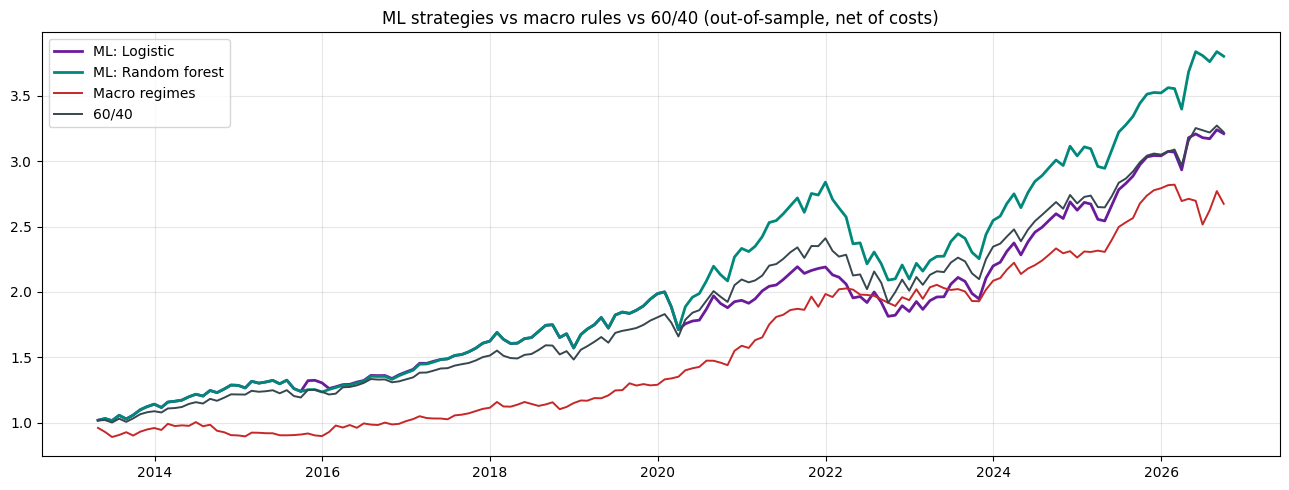

In [13]:
# Backtest of the ML strategies over the same out-of-sample period
R_test = data.loc[test, ASSET_NAMES]
ml_strategies = {}
for name in models:
    w_eq = np.where(prob[name][test] > 0.5, 0.8, 0.2)
    weights = pd.DataFrame({"us_equities": w_eq, "treasuries_7_10y": 1 - w_eq}, index=test)
    ml_strategies[f"ML: {name}"] = backtest(weights.reindex(columns=ASSET_NAMES).fillna(0.0), R_test)
ml_strategies["Macro regimes"] = backtest(macro_weights.loc[test], R_test)
ml_strategies["60/40"] = backtest(constant_weights({"us_equities": 0.6, "treasuries_7_10y": 0.4}, test), R_test)

ml_table = pd.DataFrame({k: performance(v) for k, v in ml_strategies.items()}).T
print(f"Out-of-sample period: {test[1]:%Y-%m} -> {test[-1]:%Y-%m}")
display(ml_table)

fig, ax = plt.subplots(figsize=(13, 5))
ml_colors = ["#6a1b9a", "#00897b", "#c62828", "#37474f"]
for (name, r), color in zip(ml_strategies.items(), ml_colors):
    ax.plot((1 + r).cumprod(), label=name, color=color, lw=2 if name.startswith("ML") else 1.4)
ax.set_title("ML strategies vs macro rules vs 60/40 (out-of-sample, net of costs)")
ax.legend()
fig.tight_layout()
fig.savefig("figures/05_ml_backtest.png", dpi=150)
plt.show()

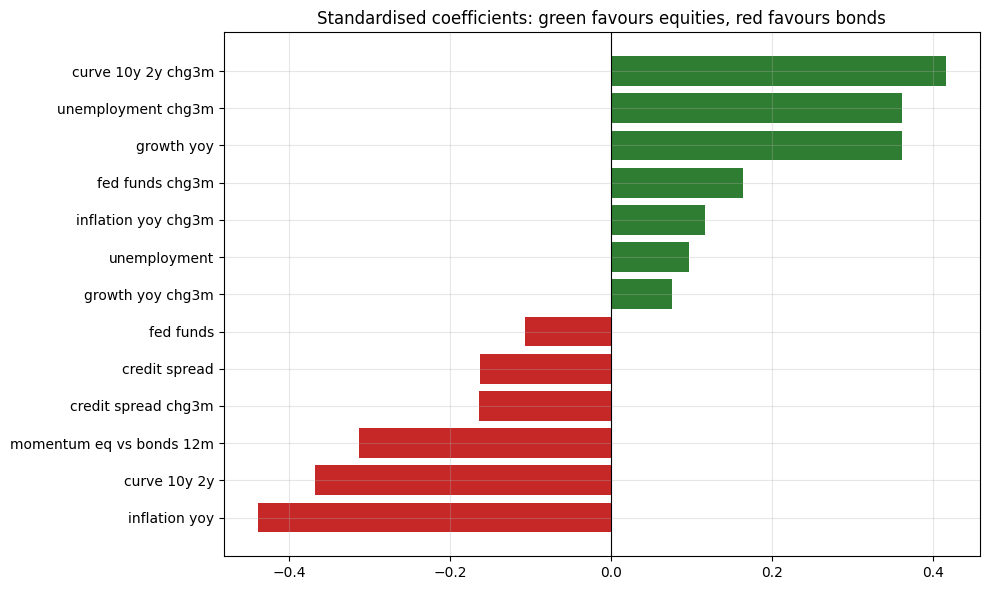

In [14]:
# Which variables matter? Coefficients of the logistic model trained on the full sample.
# WARNING: this is a descriptive in-sample analysis, not evidence of predictive power.
final_model = models["Logistic"]().fit(X, y)
coef = pd.Series(final_model[-1].coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(coef.index.str.replace("_", " "), coef.values,
        color=np.where(coef.values > 0, "#2e7d32", "#c62828"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Standardised coefficients: green favours equities, red favours bonds")
fig.tight_layout()
fig.savefig("figures/06_logistic_coefficients.png", dpi=150)
plt.show()

## Step 6: Conclusions and limitations

### How to read the results
- **Step 3:** the four-regime theory holds if the heatmap colours follow the theoretical table (equities strong in Goldilocks, bonds in Deflation, gold and commodities when inflation rises). The cells with an asterisk, i.e. statistically significant, matter most. With few months per regime many will not be significant, and that is a finding too.
- **Step 4:** judge the macro strategy mainly on **Sharpe ratio and drawdown**, not just return. A macro approach rarely beats equities in a bull market, but it can protect during crises.
- **Step 5:** if the ML models do not beat the naive model, that is the most likely and most honest conclusion. Forecasting markets with monthly macro data is hard, because prices incorporate expectations well before the data are released.

### Limitations
1. **Data revisions.** FRED provides today's revised data, not what the market saw at the time. The rigorous solution is to use real-time vintages from **ALFRED**.
2. **Short sample.** Roughly 17 years and four regimes leave few observations per regime, so results are statistically fragile.
3. **Arbitrary choices.** The regime threshold (12-month average), the weights and the model parameters are choices. Try enough combinations and one will "work" by chance (*data snooping*).
4. **Simplified costs.** Drift rebalancing, variable bid-ask spreads and taxes are not included.
5. **US only.** Results may not hold for Europe or other markets.

### Possible extensions
- Use macro **surprises** (actual release minus consensus) instead of levels.
- Add **monetary policy** regimes (Fed hiking vs cutting cycles).
- Repeat the analysis for the **euro area** with ECB/Eurostat data.
- Replace the hand-made regimes with a statistical model such as a **Hidden Markov Model**.